# 02 · Comparación 2024 vs 2025 (antes de unir y limpiar a fondo)

**Responsable:** Magno Luque · **Proyecto:** YAWAR (Hackathon FACI 2026, UPCH)

## Para qué sirve este cuaderno
Antes de usar 2024 para algo (validar el modelo, mostrar una tendencia), hay que saber si los dos años **se parecen** en lo básico. Responde tres preguntas:

1. ¿Los niños de 2024 y de 2025 tienen una **composición parecida** (edad, área, región, altitud)?
2. ¿Los **controles CRED** se registran de forma comparable?
3. ¿Las **tasas básicas** de "recibió hierro" y "tomó hierro en los últimos 7 días" son del mismo orden en los dos años?

> **Importante:** todas las cifras de este cuaderno son **sin ponderar** y sin intervalos de confianza. Describen a los niños que aparecen en la encuesta, **no a los niños del Perú**. Sirven para comparar la estructura de los dos años; las cifras ponderadas llegan en el cuaderno 04 y esas son las únicas que van al pitch.

## Decisiones de partida (preliminares)
- **Universo:** niños de **6 a 35 meses** (el rango que propone el plan del equipo).
- **Edad:** calculada como fecha de entrevista menos fecha de nacimiento (`V008 − B3`). Es la propuesta del cuaderno 01 (completa para todos los niños); queda por confirmar con Jose.
- **"Recibió hierro":** `sí` si alguna de las cuatro presentaciones (`S465DB_A` a `D`) es 1; `no` si ninguna es 1; `no sabe` si no hay ningún 1 pero hay algún 8; `vacío` si no se preguntó.
- **"Tomó hierro en 7 días":** misma regla con `S465EA` a `ED`.
- La cohorte final no se fija aquí; este cuaderno solo explora.

In [1]:
import sys
sys.path.insert(0, ".")

import pandas as pd
from rutas import leer

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)

## 1. Armar la tabla de trabajo de cada año
Reunimos en una sola tabla, por niño, lo que necesitamos de cada módulo. Unimos por `CASEID` más el índice del niño (en el cuaderno 01 vimos que no se pierde ningún niño). **Esta tabla vive solo en este cuaderno**; la tabla limpia oficial se construye en el 03.

In [2]:
DEPARTAMENTOS = {
    "1": "Amazonas", "2": "Áncash", "3": "Apurímac", "4": "Arequipa", "5": "Ayacucho", "6": "Cajamarca",
    "7": "Callao", "8": "Cusco", "9": "Huancavelica", "10": "Huánuco", "11": "Ica", "12": "Junín",
    "13": "La Libertad", "14": "Lambayeque", "15": "Lima", "16": "Loreto", "17": "Madre de Dios",
    "18": "Moquegua", "19": "Pasco", "20": "Piura", "21": "Puno", "22": "San Martín", "23": "Tacna",
    "24": "Tumbes", "25": "Ucayali",
}
REGION_NATURAL = {"1": "Lima Metropolitana", "2": "Resto Costa", "3": "Sierra", "4": "Selva"}
AREA = {"1": "Urbano", "2": "Rural"}
PRES_RECIBIO = ["S465DB_A", "S465DB_B", "S465DB_C", "S465DB_D"]
PRES_TOMO = ["S465EA", "S465EB", "S465EC", "S465ED"]


def estado(df, cols):
    # Resume varias preguntas de hierro en: sí / no / no sabe / vacío.
    v = df[cols]
    resultado = pd.Series("no", index=df.index)
    resultado[(v == "8").any(axis=1)] = "no sabe"
    resultado[(v == "1").any(axis=1)] = "sí"
    resultado[v.isna().all(axis=1)] = "vacío"
    return resultado


def construir_base(anio):
    r95 = leer(anio, "1634", "REC95", ["CASEID", "IDX95", "S466", "S466C"] + PRES_RECIBIO + PRES_TOMO)
    r44 = leer(anio, "1638", "REC44", ["CASEID", "HWIDX", "HW1"]).rename(columns={"HWIDX": "IDX95"})
    r21 = leer(anio, "1632", "REC21", ["CASEID", "BIDX", "B3"]).rename(columns={"BIDX": "IDX95"})
    r011 = leer(anio, "1631", "REC0111", ["CASEID", "V008", "V021", "V024", "V025", "V040"])
    r91 = leer(anio, "1631", "REC91", ["CASEID", "SREGION"])
    for d in (r95, r44, r21):
        d["IDX95"] = pd.to_numeric(d["IDX95"]).astype("Int64")
    base = (r95.merge(r44, on=["CASEID", "IDX95"], how="left")
               .merge(r21, on=["CASEID", "IDX95"], how="left")
               .merge(r011, on="CASEID", how="left")
               .merge(r91, on="CASEID", how="left"))
    assert len(base) == len(r95), "la unión duplicó o perdió niños"

    base["año"] = anio
    base["edad_m"] = pd.to_numeric(base["V008"]) - pd.to_numeric(base["B3"])
    base["banda_edad"] = pd.cut(base["edad_m"], [5, 11, 23, 35], labels=["6-11 m", "12-23 m", "24-35 m"])
    base["área"] = base["V025"].map(AREA)
    base["región natural"] = base["SREGION"].map(REGION_NATURAL)
    base["departamento"] = base["V024"].map(DEPARTAMENTOS)
    base["altitud_m"] = pd.to_numeric(base["V040"])
    base["banda_altitud"] = pd.cut(base["altitud_m"], [-1, 999, 2499, 6000],
                                   labels=["menos de 1 000 m", "1 000 a 2 499 m", "2 500 m o más"])
    base["recibió"] = estado(base, PRES_RECIBIO)
    base["tomó 7d"] = estado(base, PRES_TOMO)
    return base


bases = {a: construir_base(a) for a in (2024, 2025)}
for a, b in bases.items():
    print(f"{a}: {len(b)} niños menores de 5 años en la tabla de trabajo")

2024: 19751 niños menores de 5 años en la tabla de trabajo
2025: 18841 niños menores de 5 años en la tabla de trabajo


## 2. Tamaño del universo (6 a 35 meses)

In [3]:
filas = []
for a, b in bases.items():
    u = b[b["edad_m"].between(6, 35)]
    filas.append({
        "año": a,
        "niños menores de 5 años": len(b),
        "de 6 a 35 meses": len(u),
        "…con 'recibió' en sí o no": int(u["recibió"].isin(["sí", "no"]).sum()),
        "…con 'recibió' = no sabe": int((u["recibió"] == "no sabe").sum()),
        "…con 'recibió' vacío": int((u["recibió"] == "vacío").sum()),
    })
print(pd.DataFrame(filas).set_index("año").T.to_string())

universo = pd.concat([b[b["edad_m"].between(6, 35)] for b in bases.values()], ignore_index=True)

año                         2024   2025
niños menores de 5 años    19751  18841
de 6 a 35 meses            10197   9589
…con 'recibió' en sí o no  10079   9504
…con 'recibió' = no sabe       2      2
…con 'recibió' vacío         116     83


## 3. ¿Se parecen los dos años en su composición?
Para cada característica mostramos el **porcentaje de niños** en cada categoría, en cada año, y la **diferencia en puntos porcentuales** (pp). Una diferencia de pocos puntos es normal en una encuesta; marcamos con `*` las de **3 pp o más** para mirarlas con más cuidado.

In [4]:
def comparar(universo, columna, orden=None, minimo_pp=3.0):
    t = pd.crosstab(universo[columna], universo["año"], normalize="columns") * 100
    n = pd.crosstab(universo[columna], universo["año"])
    if orden:
        t, n = t.reindex(orden), n.reindex(orden)
    out = pd.DataFrame({
        "n 2024": n[2024], "n 2025": n[2025],
        "% 2024": t[2024].round(1), "% 2025": t[2025].round(1),
    })
    out["dif. (pp)"] = (out["% 2025"] - out["% 2024"]).round(1)
    out[""] = ["*" if abs(x) >= minimo_pp else "" for x in out["dif. (pp)"]]
    return out

for titulo, col, orden in [
    ("Edad", "banda_edad", ["6-11 m", "12-23 m", "24-35 m"]),
    ("Área", "área", ["Urbano", "Rural"]),
    ("Región natural", "región natural", ["Lima Metropolitana", "Resto Costa", "Sierra", "Selva"]),
    ("Altitud del conglomerado", "banda_altitud", ["menos de 1 000 m", "1 000 a 2 499 m", "2 500 m o más"]),
]:
    print(f"=== {titulo} (niños de 6 a 35 meses, sin ponderar) ===")
    print(comparar(universo, col, orden).to_string(), "\n")

=== Edad (niños de 6 a 35 meses, sin ponderar) ===
            n 2024  n 2025  % 2024  % 2025  dif. (pp)  
banda_edad                                             
6-11 m        2104    1986    20.6    20.7        0.1  
12-23 m       4063    3810    39.8    39.7       -0.1  
24-35 m       4030    3793    39.5    39.6        0.1   

=== Área (niños de 6 a 35 meses, sin ponderar) ===
        n 2024  n 2025  % 2024  % 2025  dif. (pp)   
área                                                
Urbano    7070    6940    69.3    72.4        3.1  *
Rural     3127    2649    30.7    27.6       -3.1  * 

=== Región natural (niños de 6 a 35 meses, sin ponderar) ===
                    n 2024  n 2025  % 2024  % 2025  dif. (pp)  
región natural                                                 
Lima Metropolitana    1095    1164    10.7    12.1        1.4  
Resto Costa           3099    2906    30.4    30.3       -0.1  
Sierra                3255    2826    31.9    29.5       -2.4  
Selva                

### Por departamento
Son 25 categorías, así que pueden aparecer diferencias grandes solo por el azar del muestreo. Mostramos todas, ordenadas por tamaño, y marcamos las de 1,5 pp o más.

In [5]:
dep = comparar(universo, "departamento", minimo_pp=1.5)
dep["n total"] = dep["n 2024"] + dep["n 2025"]
print(dep.sort_values("n total", ascending=False).drop(columns="n total").to_string())

               n 2024  n 2025  % 2024  % 2025  dif. (pp)  
departamento                                              
Lima             1118    1177    11.0    12.3        1.3  
Ucayali           469     445     4.6     4.6        0.0  
San Martín        397     482     3.9     5.0        1.1  
Loreto            427     433     4.2     4.5        0.3  
Piura             462     397     4.5     4.1       -0.4  
Amazonas          430     422     4.2     4.4        0.2  
Ica               418     433     4.1     4.5        0.4  
Tumbes            434     408     4.3     4.3        0.0  
Huánuco           418     404     4.1     4.2        0.1  
Lambayeque        404     401     4.0     4.2        0.2  
Madre de Dios     394     381     3.9     4.0        0.1  
Ayacucho          389     361     3.8     3.8        0.0  
La Libertad       391     356     3.8     3.7       -0.1  
Junín             382     347     3.7     3.6       -0.1  
Callao            335     349     3.3     3.6        0.3

## 4. Controles CRED
El contrato del equipo pide `controles_cred` en el padrón. En ENDES hay dos variables: `S466` (¿le hicieron algún control de crecimiento y desarrollo?) y `S466C` (cantidad de controles). Miramos si se comportan igual en los dos años y si el número tiene sentido como "controles recientes".

In [6]:
print("=== S466: ¿le hicieron algún control de crecimiento y desarrollo? (6-35 m, sin ponderar) ===")
print(comparar(universo.assign(S466=universo["S466"].fillna("(vacío)")), "S466").to_string(), "\n")

u = universo.copy()
u["controles"] = pd.to_numeric(u["S466C"])
validos = u[(u["controles"] <= 40)]
print("=== S466C: cantidad de controles (excluyendo 98 = no sabe), por banda de edad y año ===")
print(validos.groupby(["año", "banda_edad"], observed=True)["controles"].describe()[["count", "mean", "25%", "50%", "75%", "max"]].round(1).to_string())
print("\nNiños con S466C = 98 (no sabe):", u.groupby("año")["controles"].apply(lambda s: int((s == 98).sum())).to_dict())
print("\nLectura: si la mediana de controles crece con la edad, el número cuenta TODOS los controles desde el nacimiento,")
print("no los 'recientes'. Eso importa para decidir qué significa `controles_cred` en el padrón.")

=== S466: ¿le hicieron algún control de crecimiento y desarrollo? (6-35 m, sin ponderar) ===
         n 2024  n 2025  % 2024  % 2025  dif. (pp)  
S466                                                
(vacío)      79      64     0.8     0.7       -0.1  
0          1378    1043    13.5    10.9       -2.6  
1          8737    8478    85.7    88.4        2.7  
8             3       4     0.0     0.0        0.0   

=== S466C: cantidad de controles (excluyendo 98 = no sabe), por banda de edad y año ===
                  count  mean   25%   50%   75%   max
año  banda_edad                                      
2024 6-11 m      2083.0   9.9   8.0  10.0  12.0  26.0
     12-23 m     4004.0  14.3  12.0  15.0  17.0  33.0
     24-35 m     3950.0  16.5  12.0  18.0  21.0  40.0
2025 6-11 m      1975.0  10.1   8.0  10.0  12.0  24.0
     12-23 m     3755.0  15.1  13.0  16.0  18.0  29.0
     24-35 m     3733.0  18.0  15.0  19.0  22.0  36.0

Niños con S466C = 98 (no sabe): {2024: 81, 2025: 62}

Lectura: si 

## 5. Tasas básicas de hierro (sin ponderar)
Dos preguntas, en el universo de 6 a 35 meses:

- **Recibió:** de los niños con respuesta clara (sí o no), ¿qué porcentaje recibió hierro del MINSA en los últimos 12 meses?
- **Tomó:** de los que **sí recibieron** y tienen respuesta clara, ¿qué porcentaje tomó hierro en los últimos 7 días?

La segunda es el grupo que más le interesa al proyecto (niños que recibieron hierro pero quizá no lo toman). Aviso: un niño que ya terminó su esquema también aparece como "no tomó", así que "no tomó" **no equivale a abandono**.

In [7]:
def tasas(universo, por):
    filas = []
    for (anio, grupo), d in universo.groupby(["año", por], observed=True):
        base_rec = d[d["recibió"].isin(["sí", "no"])]
        rec = base_rec[base_rec["recibió"] == "sí"]
        base_tomo = rec[rec["tomó 7d"].isin(["sí", "no"])]
        filas.append({
            "año": anio, por: grupo,
            "n con resp. recibió": len(base_rec),
            "% recibió": round(100 * len(rec) / len(base_rec), 1) if len(base_rec) else float("nan"),
            "n recibieron con resp. tomó": len(base_tomo),
            "% tomó 7d": round(100 * (base_tomo["tomó 7d"] == "sí").mean(), 1) if len(base_tomo) else float("nan"),
        })
    t = pd.DataFrame(filas).set_index([por, "año"]).sort_index()
    return t

total = universo.assign(todos="Todos los niños de 6-35 m")
print("=== Total ===");           print(tasas(total, "todos").to_string(), "\n")
print("=== Por edad ===");        print(tasas(universo, "banda_edad").to_string(), "\n")
print("=== Por área ===");        print(tasas(universo, "área").to_string(), "\n")
print("=== Por región natural ==="); print(tasas(universo, "región natural").to_string())

=== Total ===
                                n con resp. recibió  % recibió  n recibieron con resp. tomó  % tomó 7d
todos                     año                                                                         
Todos los niños de 6-35 m 2024                10079       72.9                         7344       40.4
                          2025                 9504       75.5                         7172       45.6 

=== Por edad ===
                 n con resp. recibió  % recibió  n recibieron con resp. tomó  % tomó 7d
banda_edad año                                                                         
12-23 m    2024                 4014       79.1                         3174       33.0
           2025                 3774       80.6                         3039       42.3
24-35 m    2024                 3980       60.7                         2415       29.2
           2025                 3753       66.0                         2476       33.0
6-11 m     2024            

### Respuestas "no sabe" y vacías
Antes de cerrar, mostramos cuántos niños quedan fuera de las tasas por no tener respuesta clara. Si fueran muchos o cambiaran entre años, afectarían la comparación.

In [8]:
for var in ("recibió", "tomó 7d"):
    t = pd.crosstab(universo[var], universo["año"])
    p = (pd.crosstab(universo[var], universo["año"], normalize="columns") * 100).round(1)
    print(f"=== {var} (6-35 m): conteo y % por año, sin ponderar ===")
    print(pd.concat({"n": t, "%": p}, axis=1).to_string(), "\n")

=== recibió (6-35 m): conteo y % por año, sin ponderar ===
            n           %      
año      2024  2025  2024  2025
recibió                        
no       2732  2329  26.8  24.3
no sabe     2     2   0.0   0.0
sí       7347  7175  72.1  74.8
vacío     116    83   1.1   0.9 

=== tomó 7d (6-35 m): conteo y % por año, sin ponderar ===
            n           %      
año      2024  2025  2024  2025
tomó 7d                        
no       6635  5802  65.1  60.5
no sabe     3     5   0.0   0.1
sí       3443  3699  33.8  38.6
vacío     116    83   1.1   0.9 



## Gráficos de este cuaderno
**Composición (sin ponderar):** cada punto es el porcentaje de niños en esa categoría. Si el punto azul (2024) y el naranja (2025) casi se tocan, los dos años se parecen y se pueden comparar sin preocupación.

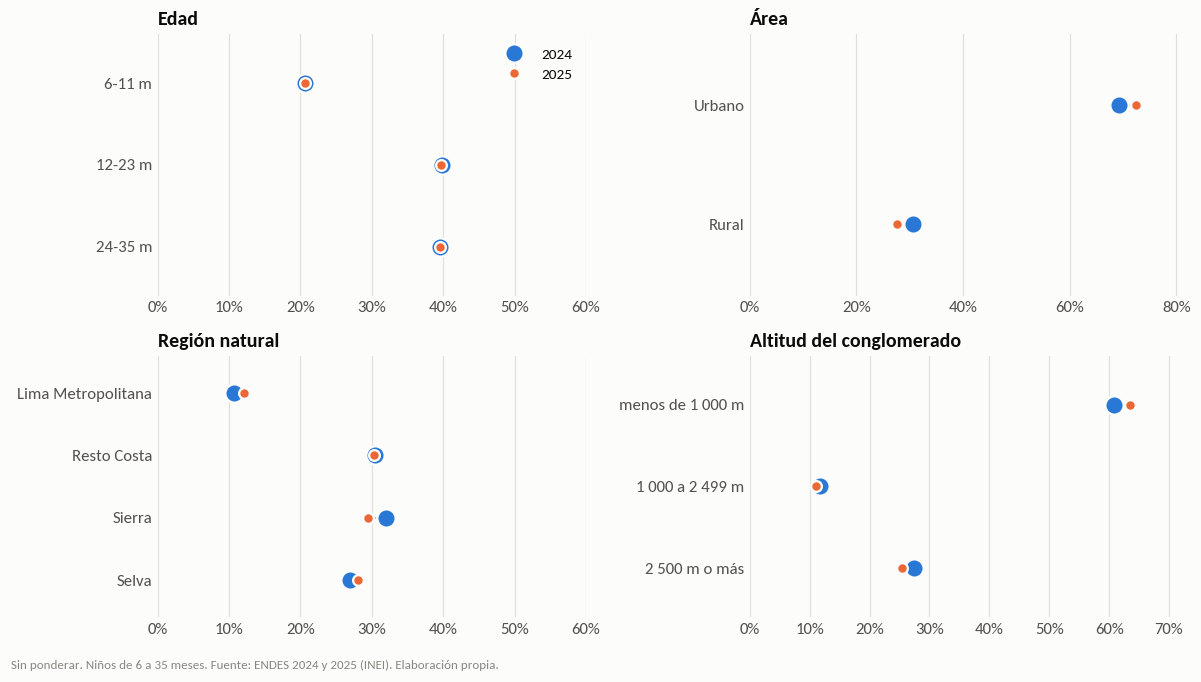

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import graficos as g

PANELES = [("Edad", "banda_edad", ["6-11 m", "12-23 m", "24-35 m"]),
           ("Área", "área", ["Urbano", "Rural"]),
           ("Región natural", "región natural", ["Lima Metropolitana", "Resto Costa", "Sierra", "Selva"]),
           ("Altitud del conglomerado", "banda_altitud", ["menos de 1 000 m", "1 000 a 2 499 m", "2 500 m o más"])]
fig, axs = plt.subplots(2, 2, figsize=(11, 6.2))
for ax, (titulo, col, orden) in zip(axs.ravel(), PANELES):
    t = pd.crosstab(universo[col], universo["año"], normalize="columns").reindex(orden) * 100
    y = np.arange(len(orden))[::-1]
    for yi, (_, fila_t) in zip(y, t.iterrows()):
        ax.plot([fila_t[2024], fila_t[2025]], [yi, yi], color=g.EJE, linewidth=1.4, zorder=1)
    for anio in (2024, 2025):
        ax.plot(t[anio].values, y, "o", color=g.COLOR_ANIO[anio], markersize=(12 if anio == 2024 else 7), markeredgecolor=g.SUPERFICIE, markeredgewidth=1.5, label=str(anio), zorder=(3 if anio == 2024 else 4))
    ax.set_yticks(y)
    ax.set_yticklabels(orden)
    ax.set_xlim(0, max(60, float(t.values.max()) + 8))
    ax.set_ylim(-0.6, len(orden) - 0.4)
    ax.set_title(titulo)
    g.rejilla(ax, "x")
    ax.xaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
axs[0, 0].legend(loc="upper right")
g.pie(fig, "Sin ponderar. Niños de 6 a 35 meses. Fuente: ENDES 2024 y 2025 (INEI). Elaboración propia.")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

**Tasas básicas por edad (sin ponderar):** izquierda, de los niños con respuesta clara, el porcentaje que **recibió** hierro; derecha, de los que **recibieron**, el porcentaje que **lo tomó** la última semana. Son cifras de la encuesta, no del país; las del país (ponderadas) están en el cuaderno 04.

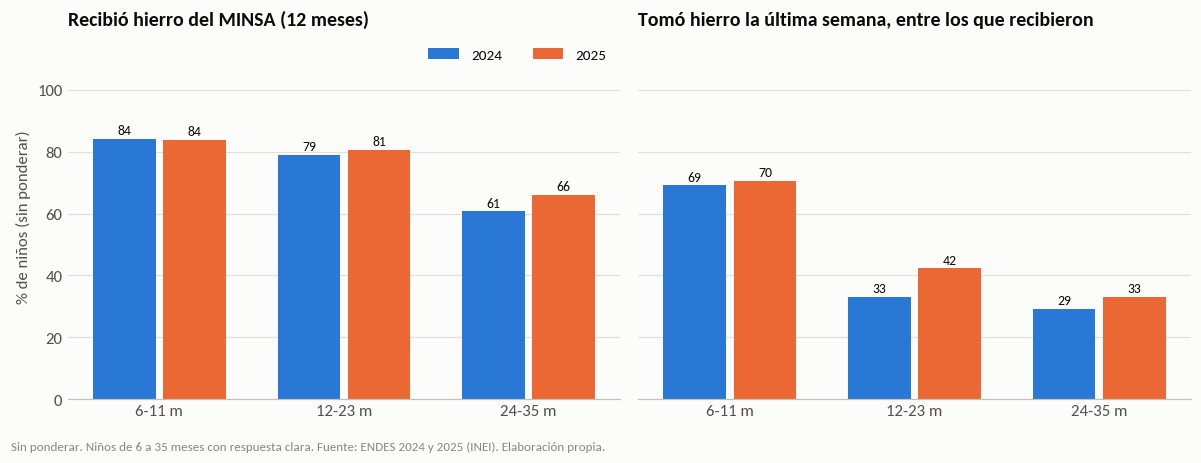

In [10]:
def tasa_por_banda(anio):
    b = universo[universo["año"] == anio]
    rec, tom = [], []
    for banda in ["6-11 m", "12-23 m", "24-35 m"]:
        d = b[b["banda_edad"] == banda]
        r = d[d["recibió"].isin(["sí", "no"])]
        rec.append(100 * (r["recibió"] == "sí").mean())
        q = r[r["recibió"] == "sí"]
        q = q[q["tomó 7d"].isin(["sí", "no"])]
        tom.append(100 * (q["tomó 7d"] == "sí").mean())
    return rec, tom

res = {a: tasa_por_banda(a) for a in (2024, 2025)}
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
x = np.arange(3)
for k, (ax, titulo) in enumerate(zip(axs, ["Recibió hierro del MINSA (12 meses)", "Tomó hierro la última semana, entre los que recibieron"])):
    for anio, desp in ((2024, -0.19), (2025, 0.19)):
        v = res[anio][k]
        ax.bar(x + desp, v, width=0.34, color=g.COLOR_ANIO[anio], label=str(anio), zorder=2)
        for xi, vi in zip(x + desp, v):
            ax.text(xi, vi + 1.5, f"{vi:.0f}", ha="center", fontsize=9, color=g.TINTA)
    ax.set_xticks(x)
    ax.set_xticklabels(["6-11 m", "12-23 m", "24-35 m"])
    ax.set_ylim(0, 118)
    ax.set_title(titulo)
    g.rejilla(ax, "y")
axs[0].set_ylabel("% de niños (sin ponderar)")
axs[0].legend(loc="upper right", ncol=2)
g.pie(fig, "Sin ponderar. Niños de 6 a 35 meses con respuesta clara. Fuente: ENDES 2024 y 2025 (INEI). Elaboración propia.")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 6. Conclusiones

### Qué se parece entre 2024 y 2025
- **Edad:** prácticamente idéntica. La diferencia por banda es de 0,1 pp o menos.
- **Región natural, departamento y altitud:** diferencias de hasta 2,6 pp; ninguna llega al umbral de 3 pp.
- **Área:** 2025 tiene **3,1 pp más niños urbanos** (69,3 % → 72,4 %). Es la única diferencia marcada con `*` en la composición.
- **Controles CRED:** "le hicieron algún control" (`S466`) sube de 85,7 % a 88,4 %, y el número de controles (`S466C`) se parece entre años.

**Lectura:** la composición de los dos años es lo bastante parecida como para que la estructura **no** sea, por sí sola, una razón para descartar 2024 como año de referencia.

### Qué cambia
- **"Tomó hierro en 7 días" entre los que recibieron sube de 40,4 % a 45,6 % (+5,2 pp)**, y el aumento es mayor en el grupo de 12 a 23 meses (33,0 % → 42,3 %). Como la mezcla de edades es idéntica, **la edad no explica ese cambio**. "Recibió" también sube, pero menos (72,9 % → 75,5 %).
- **Consecuencia para la etiqueta del modelo (aviso para quien entrene el modelo):** si la etiqueta es "no tomó", su frecuencia baja de 59,6 % en 2024 a 54,4 % en 2025. Un modelo entrenado con 2024 vería en 2025 una frecuencia distinta, y su **calibración** puede desajustarse aunque ordene bien a los niños.
- Esto se conecta con el salto en hierro en polvo que vimos en el cuaderno 01. Todavía no sabemos si es un cambio real, de campo o de cuestionario.

### Otros hallazgos útiles
- **Tamaño preliminar de la cohorte (niños de 6 a 35 meses que recibieron hierro y con respuesta clara sobre si lo tomaron):** 7 344 en 2024 y 7 172 en 2025.
- **El "no tomó" crece con la edad,** como dice el planteamiento del proyecto: entre los que recibieron, tomaron en la última semana alrededor del 70 % a los 6-11 meses, y entre el 29 % y el 33 % a los 24-35 meses. Recordar que un niño que ya terminó su esquema también aparece como "no tomó".
- **Los porcentajes por departamento no representan a la población:** cada departamento aporta una parte parecida de la muestra (Tumbes y Madre de Dios casi tanto como Piura o La Libertad). Por eso las cifras sin ponderar **no se pueden usar para decir nada sobre el país**.
- **`S466C` (cantidad de controles) parece acumulado desde el nacimiento:** la mediana sube con la edad (10 → 15-16 → 18-19). Es una inferencia a partir de los datos, no algo que diga el diccionario. Si es así, `controles_cred` del padrón debe definirse con cuidado.

### Límites y supuestos de este cuaderno
- **Tasas sin ponderar:** la subida de "tomó" entre años se confirma con cifras ponderadas en el cuaderno 04.
- **Etiqueta "no tomó":** su frecuencia cambia entre 2024 y 2025; es relevante para cualquier modelo entrenado con un solo año.
- **`controles_cred`:** `S466C` parece acumulado desde el nacimiento; es una inferencia a partir de los datos, no algo que diga el diccionario.
- **Composición:** los dos años se parecen, con diferencias de hasta 3 puntos en área, región natural y altitud (sin ponderar).

**Siguiente cuaderno:** `03_union_y_limpieza`, que construye la tabla limpia por año con las exclusiones documentadas.